In [53]:
# library imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [23]:
# read data
full_100 = pd.read_csv("data/top_100.csv")
ones = pd.read_csv("data/billboard.csv")

In [6]:
type(all)
type(ones)

pandas.DataFrame

In [21]:
ones.columns


Index(['song', 'artist', 'date', 'weeks_at_number_one', 'non_consecutive',
       'rating_1', 'rating_2', 'rating_3', 'overall_rating', 'divisiveness',
       ...
       'featured_in_a_then_contemporary_play', 'written_for_a_film',
       'featured_in_a_then_contemporary_film', 'written_for_a_t_v_show',
       'featured_in_a_then_contemporary_t_v_show', 'associated_with_dance',
       'topped_the_charts_by_multiple_artist', 'double_a_side',
       'eurovision_entry', 'u_s_artwork'],
      dtype='str', length=105)

In [24]:
full_100.columns

Index(['Unnamed: 0', 'week', 'song', 'artist', 'this_week', 'last_week',
       'peak_position', 'weeks_on_chart'],
      dtype='str')

In [20]:
ones['artist'].head()

0        Ricky Nelson
1    Domenico Modugno
2        The Elegants
3       Tommy Edwards
4       Conway Twitty
Name: artist, dtype: str

In [84]:
reached_1_artists = full_100[full_100["peak_position"] == 1]
top_2_to_100_artists = full_100[~full_100["artist"].isin(reached_1_artists["artist"])]

In [33]:
top_2_to_100_artists['peak_position'].min()

np.int64(2)

In [ ]:
reached_1_artists['peak_position'].min()

np.int64(1)

In [39]:
top_2_to_100_artists.set_index('artist')

,Unnamed: 0,week,song,this_week,last_week,peak_position,weeks_on_chart
artist,,,,,,,
Perez Prado And His Orchestra,1,1958-08-04,Patricia,2,NaN,2,1
Kalin Twins,4,1958-08-04,When,5,NaN,5,1
Duane Eddy His Twangy Guitar And The Rebels,5,1958-08-04,Rebel-'rouser,6,NaN,6,1
The Coasters,6,1958-08-04,Yakety Yak,7,NaN,7,1
Jack Scott,7,1958-08-04,My True Love,8,NaN,8,1
...,...,...,...,...,...,...,...
boa,355679,2026-10-03,Duvet,93,NaN,93,1
Rod Wave,355681,2026-10-03,Dope Girl,95,NaN,70,3
Jhene Aiko,355682,2026-10-03,Ghost,96,42.0,42,2


In [65]:
top_2_to_100_merged = top_2_to_100_artists.merge(
    ones[['artist', 'artist_male', 'artist_white', 'artist_black']].drop_duplicates('artist'),
    on='artist',
    how='left')
    
top_2_to_100_merged.head(-10)

,Unnamed: 0,week,song,artist,this_week,last_week,peak_position,weeks_on_chart,artist_male,artist_white,artist_black
0,1,1958-08-04,Patricia,Perez Prado And His Orchestra,2,NaN,2,1,NaN,NaN,NaN
1,4,1958-08-04,When,Kalin Twins,5,NaN,5,1,NaN,NaN,NaN
2,5,1958-08-04,Rebel-'rouser,Duane Eddy His Twangy Guitar And The Rebels,6,NaN,6,1,NaN,NaN,NaN
3,6,1958-08-04,Yakety Yak,The Coasters,7,NaN,7,1,NaN,NaN,NaN
4,7,1958-08-04,My True Love,Jack Scott,8,NaN,8,1,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...
243783,355666,2026-10-03,Get To Drinkin',Zach John King,80,87.0,80,3,NaN,NaN,NaN
243784,355668,2026-10-03,Joseph,"Falling in Reverse, Corey Taylor & Serj Tankian",82,NaN,82,1,NaN,NaN,NaN
243785,355669,2026-10-03,Finders Keepers,Luke Bryan & Luke Combs,83,NaN,83,1,NaN,NaN,NaN
243786,355672,2026-10-03,Ahi,Karol G With Drake,86,88.0,44,7,NaN,NaN,NaN


In [49]:
top_2_to_100_merged.columns

Index(['Unnamed: 0', 'week', 'song', 'artist', 'this_week', 'last_week',
       'peak_position', 'weeks_on_chart', 'artist_male', 'artist_white',
       'artist_black'],
      dtype='str')

Graphs for the 2-100 artist demographics (very basic)

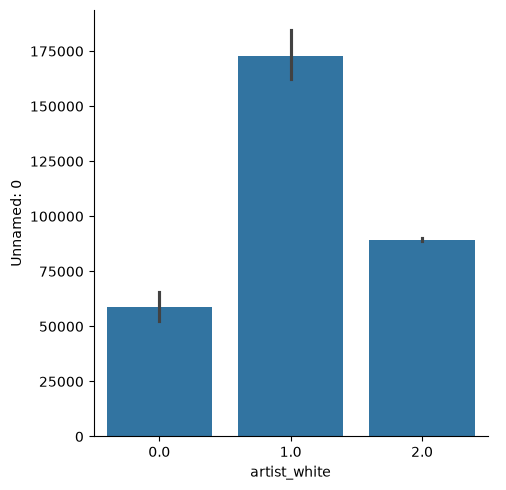

In [67]:
sns.catplot(data= top_2_to_100_merged, x='artist_white', y = 'Unnamed: 0', kind = 'bar')

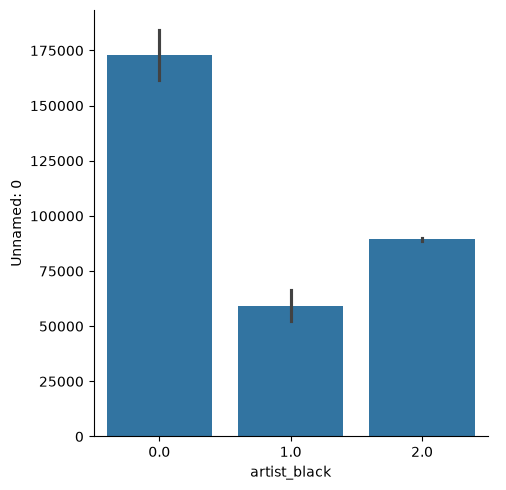

In [68]:
sns.catplot(data= top_2_to_100_merged, x='artist_black', y = 'Unnamed: 0', kind = 'bar')

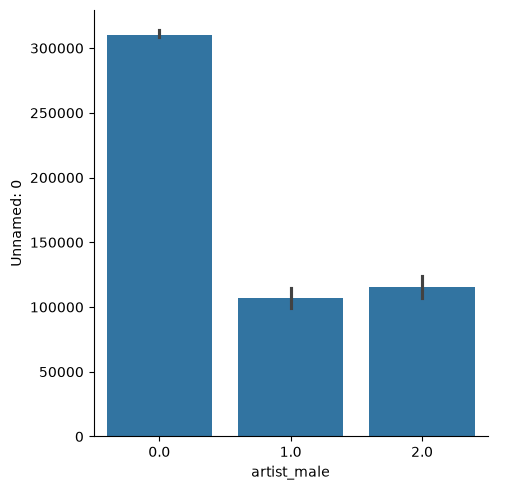

In [69]:
sns.catplot(data= top_2_to_100_merged, x='artist_male', y = 'Unnamed: 0', kind = 'bar')

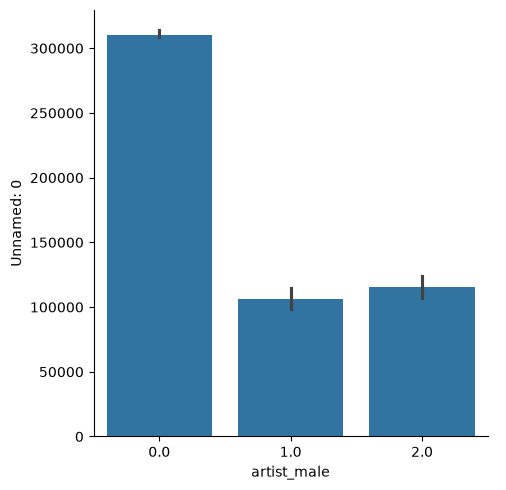

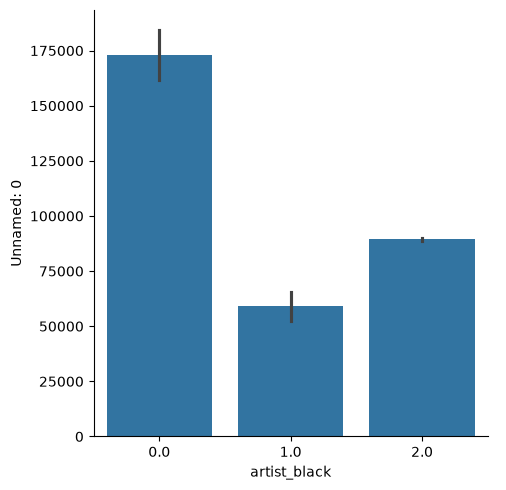

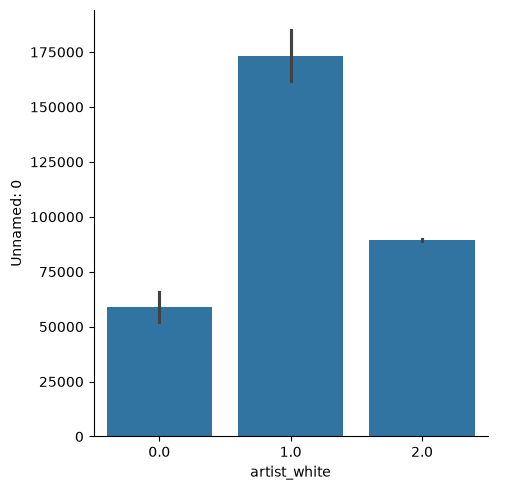

In [73]:

sns.catplot(data= top_2_to_100_merged, x='artist_male', y = 'Unnamed: 0', kind = 'bar')
sns.catplot(data= top_2_to_100_merged, x='artist_black', y = 'Unnamed: 0', kind = 'bar')
sns.catplot(data= top_2_to_100_merged, x='artist_white', y = 'Unnamed: 0', kind = 'bar')

artist_male	numeric	Dummy for if the artist were a male or a group of males at the time of the release. If 0, the artist or group was all female. If 1, the artist or group was all male. If 2, the artist has a mix of males and females. If 3, the artist contains at least one non-binary person.

artist_white	numeric	Dummy for if the artist was white, meaning that their ancestry was of European origin. If 0, the artist was not white. If 1, the artist was white. If 2, the artist has members that are both white and not white.

artist_black	numeric	Dummy for if the artist was black, meaning that their ancestry was of African origin. If 0, the artist was not black. If 1, the artist was black. If 2, the artist has members that are both black and not black.


get the artists of all of the number 1 spots
get the artists of all of the rest of the the top 100 (2-100)

figure out how to view the ages and gender of each artist 

<Axes: xlabel='week', ylabel='artist_male'>

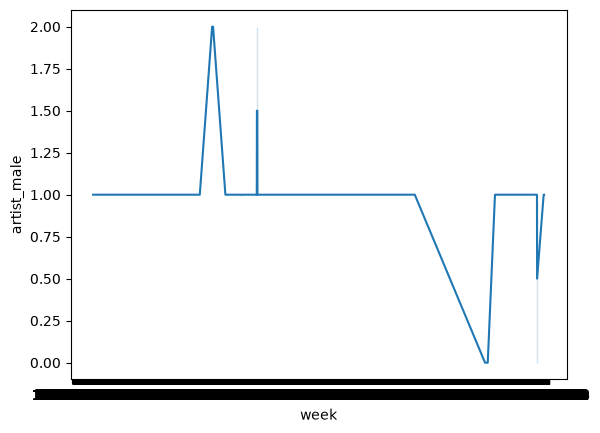

In [95]:
sns.lineplot(data=top_2_to_100_merged, x='week', y='artist_male')

would be helpful to group the songs by era, to make view information over time easier

In [99]:
reached_1_artists = reached_1_artists.merge(
    ones[['artist', 'artist_male', 'artist_white', 'artist_black']].drop_duplicates('artist'),
    on='artist',
    how='left')

MergeError: Passing 'suffixes' which cause duplicate columns {'artist_black_y', 'artist_male_x', 'artist_white_y', 'artist_male_y', 'artist_black_x', 'artist_white_x'} is not allowed.

In [100]:
reached_100_artists.columns

Index(['Unnamed: 0', 'week', 'song', 'artist', 'this_week', 'last_week',
       'peak_position', 'weeks_on_chart'],
      dtype='str')